# 10. Every assumption, and how much it matters

A model is only as credible as its assumptions. This notebook lists every condition the models rely on, shows
how one inferred condition (the bar size of the handbook's normalised data) turned out to be documented in a
second source, and measures how much each remaining assumption matters by retraining the models with it moved
to the ends of its range.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3g}")
R = ROOT / "results"; FIG = ROOT / "figures"
def fig(name, width=1000):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

In [2]:
pd.read_csv(R / "s10_assumptions.csv")

,assumption,value,status,evidence,range_tested,used_in
0,Bar size of the handbook normalised rows,25 mm (1 in.) round,documented,same values as the 25 mm rows of Birbilis et a...,"13, 25, 50 mm",property models (stage 4)
1,Furnace cooling rate of the handbook annealed ...,0.005 K/s at 700 C (18 K/h),inferred,usual full-annealing practice (10-50 K/h); phy...,0.002-0.02 K/s,property models (stage 4)
2,Austenitising temperatures of handbook / Birbi...,as stated in the sources,documented,"given for 100 % of handbook rows, 72 % of norm...",-,all stages
3,Default austenitising rules (anneal / normalis...,Ae3+50 / upper+110 (>=870) / Ae3+70 C,fitted,MAE 14 / 15 / 16 C against the handbook and Bi...,-,predictor defaults
4,Still-air heat transfer,"laminar natural convection + radiation, emissi...",literature,agrees with measured 25 and 45-50 mm bar cooli...,emissivity 0.6-0.9; convection x0.7-1.3,normalising paths
5,Prior-austenite grain size,"ASTM 8 at 850 C, one number coarser per 100 C",assumed,fine-grained Al-killed practice (ASTM E112 cha...,-1 to +1 ASTM number,"kinetics, Hall-Petch"
6,Quench severity,"Grossmann H, middle of the 'mild agitation' class",literature,"Grossmann et al. 1939 table; oil 0.30-0.35, wa...",low and high end of the class,hardening paths
7,Conductivity used to turn H into h,30 W/m/K,assumed,hot austenite 25-35 W/m/K (EN 1993-1-2),25-40 W/m/K,hardening paths
8,Specific heat during a quench,Eurocode polynomial capped at 650 J/kg/K (no 7...,assumed,the peak is the heat of slow transformation; w...,Eurocode with peak,hardening paths
9,Tensile specimen position,"centre up to 38 mm, mid-radius above (ASTM A370)",documented standard,ASTM A370 bar products,centre for every bar,Q+T models


## The handbook's normalised data are 25 mm bars
Version 2 inferred 50 mm from the physics alone. The Birbilis database has the same values with the bar size.

In [3]:
pd.read_csv(R / "s10_handbook_section_match.csv").round(1)

,section_mm,grades,mean_dUTS,rms_dUTS,within_3MPa,mean_dYS
0,13,28,41.3,69.7,2,36.2
1,25,28,0.4,2.8,21,-0.5
2,50,28,-29.1,38.7,1,-26.7
3,100,28,-55,74.6,0,-58.4


## One assumption at a time (retrained, leave one grade out)

In [4]:
pd.read_csv(R / "s10_oat_anneal_normalise.csv").round(1)

,setting,UTS_MPa_RMSE,HB_RMSE,dUTS_1020,dUTS_1045,dUTS_1080,dUTS_4140,dUTS_4340
0,baseline,62.8,19.7,42.7,102,360,360,516
1,furnace cooling 0.002 K/s,62,19.6,43.1,87.1,325,332,520
2,furnace cooling 0.01 K/s,62.5,20.9,42.6,112,393,384,520
3,furnace cooling 0.02 K/s,62.7,21.3,40.7,132,433,417,527
4,normalised bars 50 mm (v2 inference),68.1,18.7,49,134,386,488,562
5,normalised bars 13 mm,82.3,24.2,39.9,74.9,330,312,434
6,emissivity 0.6,60.1,19.7,44.6,106,358,360,515
7,emissivity 0.9,66.4,20.1,43,100,361,358,516
8,convection x0.7,59,19.4,42.4,101,360,360,517
9,convection x1.3,66.3,20.1,42.9,101,361,358,516


In [5]:
pd.read_csv(R / "s10_oat_quench_temper.csv").round(1)

,setting,greybox_UTS_RMSE,mean_f_martensite,bias_13mm,bias_25mm,bias_50mm,bias_100mm
0,baseline,99.5,0.4,-53.1,-45.9,-9.1,31.8
1,specimen at the centre of every bar,99.2,0.4,-52.9,-45.8,-8,32.3
2,tempering time 0.5 h,99.4,0.4,-52.1,-44,-8.1,32.9
3,tempering time 2 h,99.8,0.4,-53.6,-47,-9.7,31.1
4,H at the low end of the class,101,0.4,-54.7,-49,-10.5,31
5,H at the high end of the class,98.3,0.4,-51.5,-43.2,-7.4,32.6
6,conductivity for H->h 25 W/m/K,102,0.4,-57.2,-53.5,-12.4,29.6
7,conductivity for H->h 40 W/m/K,94.9,0.5,-47.7,-35.9,-1.4,35.2
8,Hollomon-Jaffe C = 18,99.7,0.4,-48.8,-42.5,-8.4,32.1
9,Hollomon-Jaffe C = 22,100,0.4,-52.6,-48.3,-10,30.1


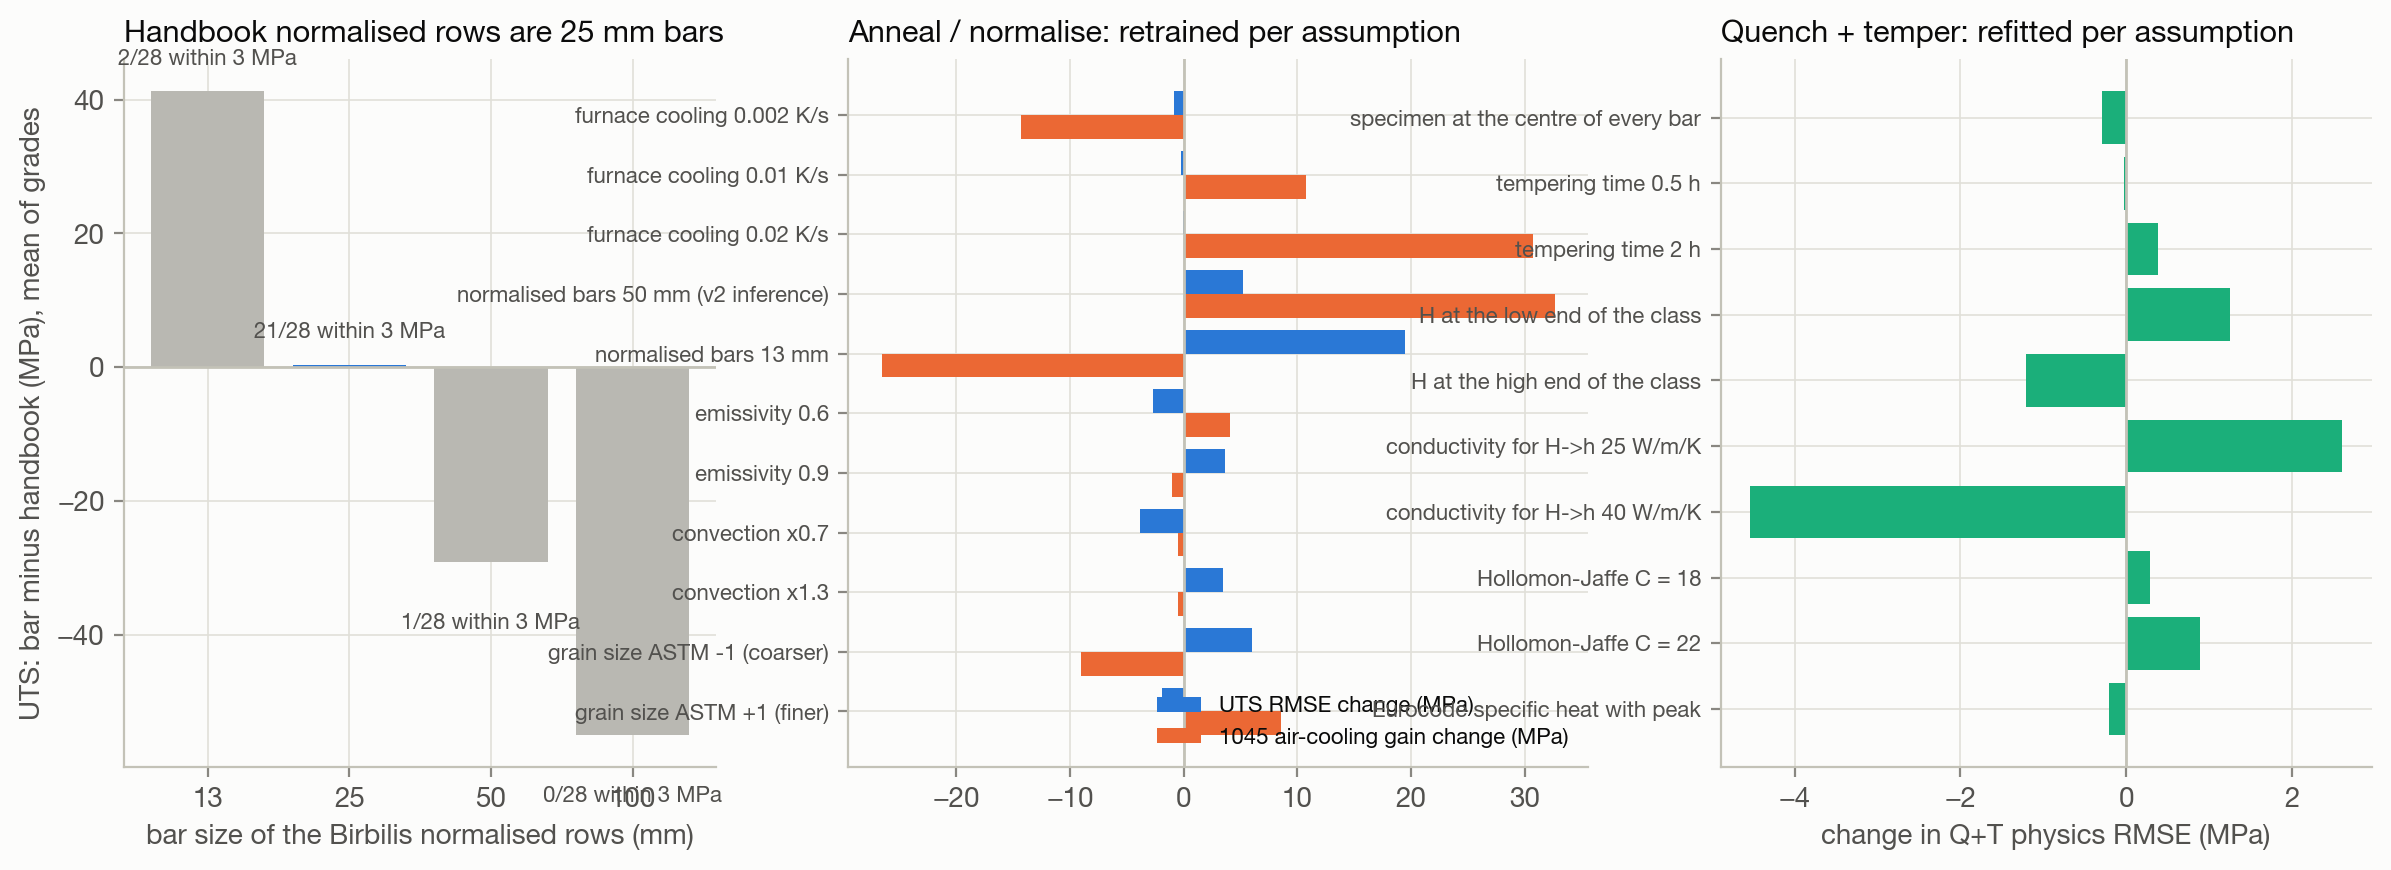

In [6]:
fig("fig38_assumption_sensitivity", 1100)

## Global sensitivity (Morris elementary effects)

In [7]:
pd.read_csv(R / "s10_morris.csv").pivot_table(index="factor", columns="output", values="mu_star").round(2)

output,UTS_QT_4140_50mm,dUTS_AC_FC_1045,dUTS_AC_FC_4140,f_martensite_4140_50mm_oil
factor,,,,
H_oil,4.94,0,0,0.33
astm,0,33.2,23.2,0.28
chj,295,0,0,0
eps,0,22.1,28.9,0
fc_rate,0,0.69,78.7,0
hconv,0,11,12.7,0
kref,4.7,0,0,0.31
t_temper,45.2,0,0,0


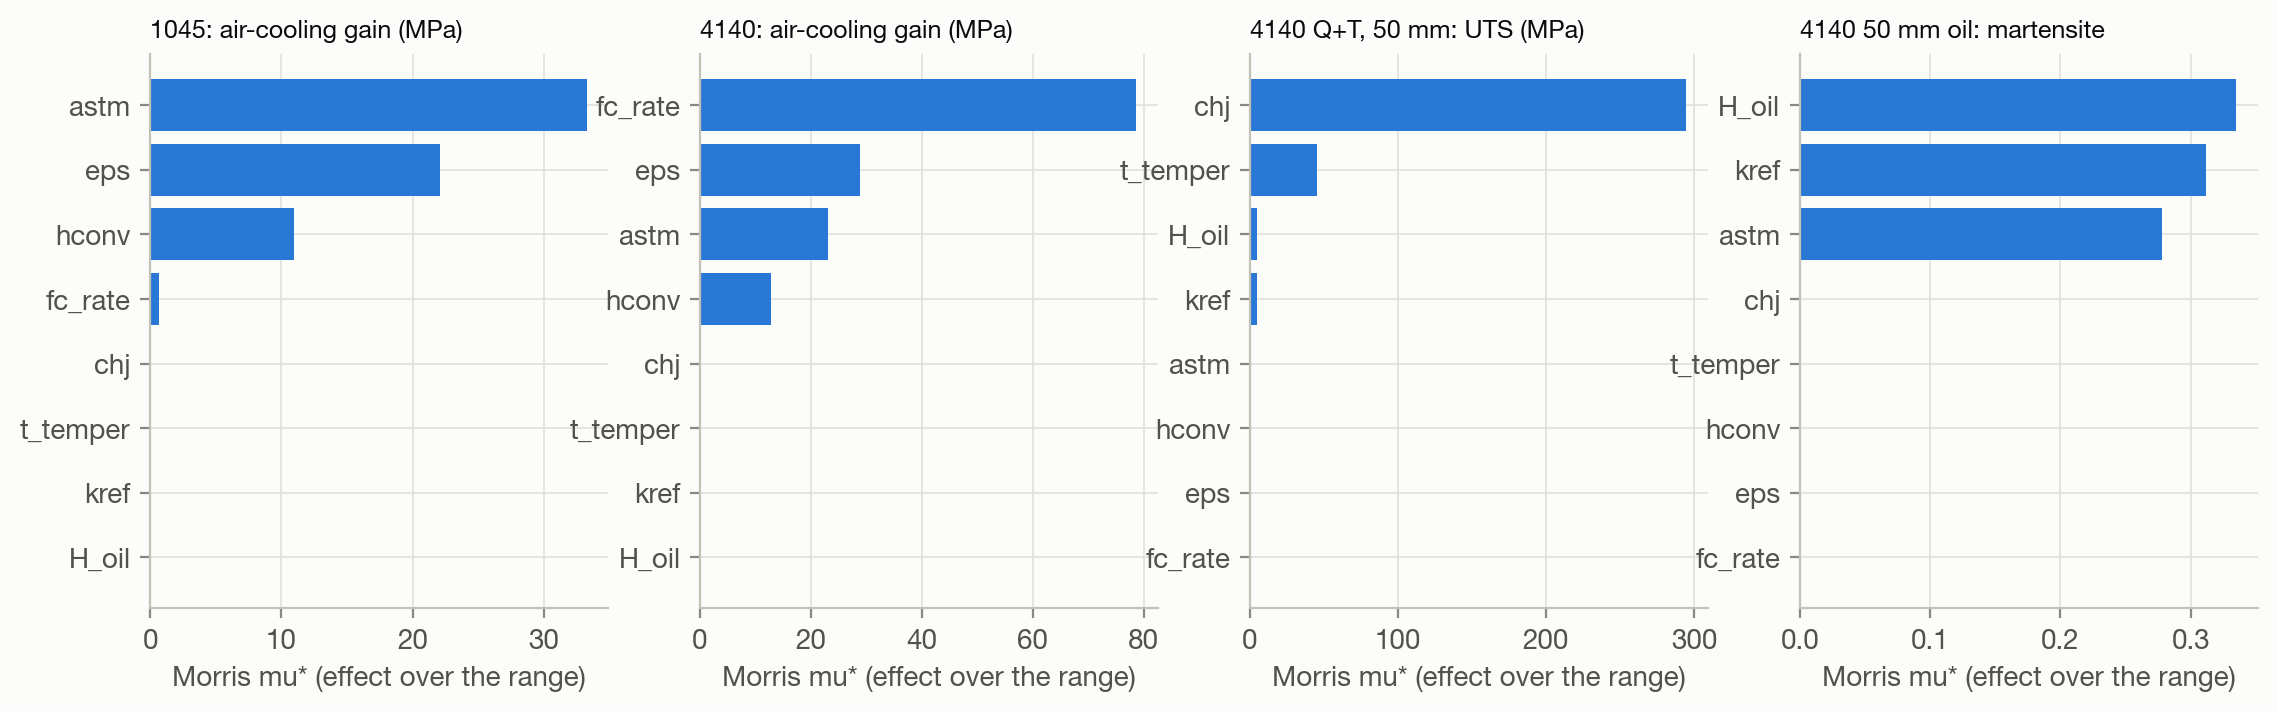

In [8]:
fig("fig39_morris_sensitivity", 1100)

## A test across bar sizes
Normalised bars of 13-100 mm and grades never seen in training.

In [9]:
pd.read_csv(R / "s06_bar_sizes_metrics.csv").round(2)

,check,target,n,grades,RMSE,bias,coverage90,sign_agreement,mean_measured,mean_predicted
0,repeats training rows,UTS_MPa,88,32,15.9,-0.68,0.99,NaN,NaN,NaN
1,repeats training rows,YS_MPa,88,32,22.7,-2.37,0.95,NaN,NaN,NaN
2,repeats training rows,El_pct,88,32,1.45,0.36,0.98,NaN,NaN,NaN
3,"normalised, handbook grades, other bar sizes",UTS_MPa,86,28,64.2,-8.39,0.88,NaN,NaN,NaN
4,"normalised, handbook grades, other bar sizes",YS_MPa,86,28,61.7,-5.26,0.91,NaN,NaN,NaN
5,"normalised, handbook grades, other bar sizes",El_pct,86,28,2.29,0.33,0.97,NaN,NaN,NaN
6,"normalised, grades never seen",UTS_MPa,28,7,79.9,-8.75,0.82,NaN,NaN,NaN
7,"normalised, grades never seen",YS_MPa,28,7,64,-16.5,0.89,NaN,NaN,NaN
8,"normalised, grades never seen",El_pct,28,7,2.69,0.25,1,NaN,NaN,NaN
9,"annealed, grades never seen",UTS_MPa,8,7,19.7,-2.58,1,NaN,NaN,NaN


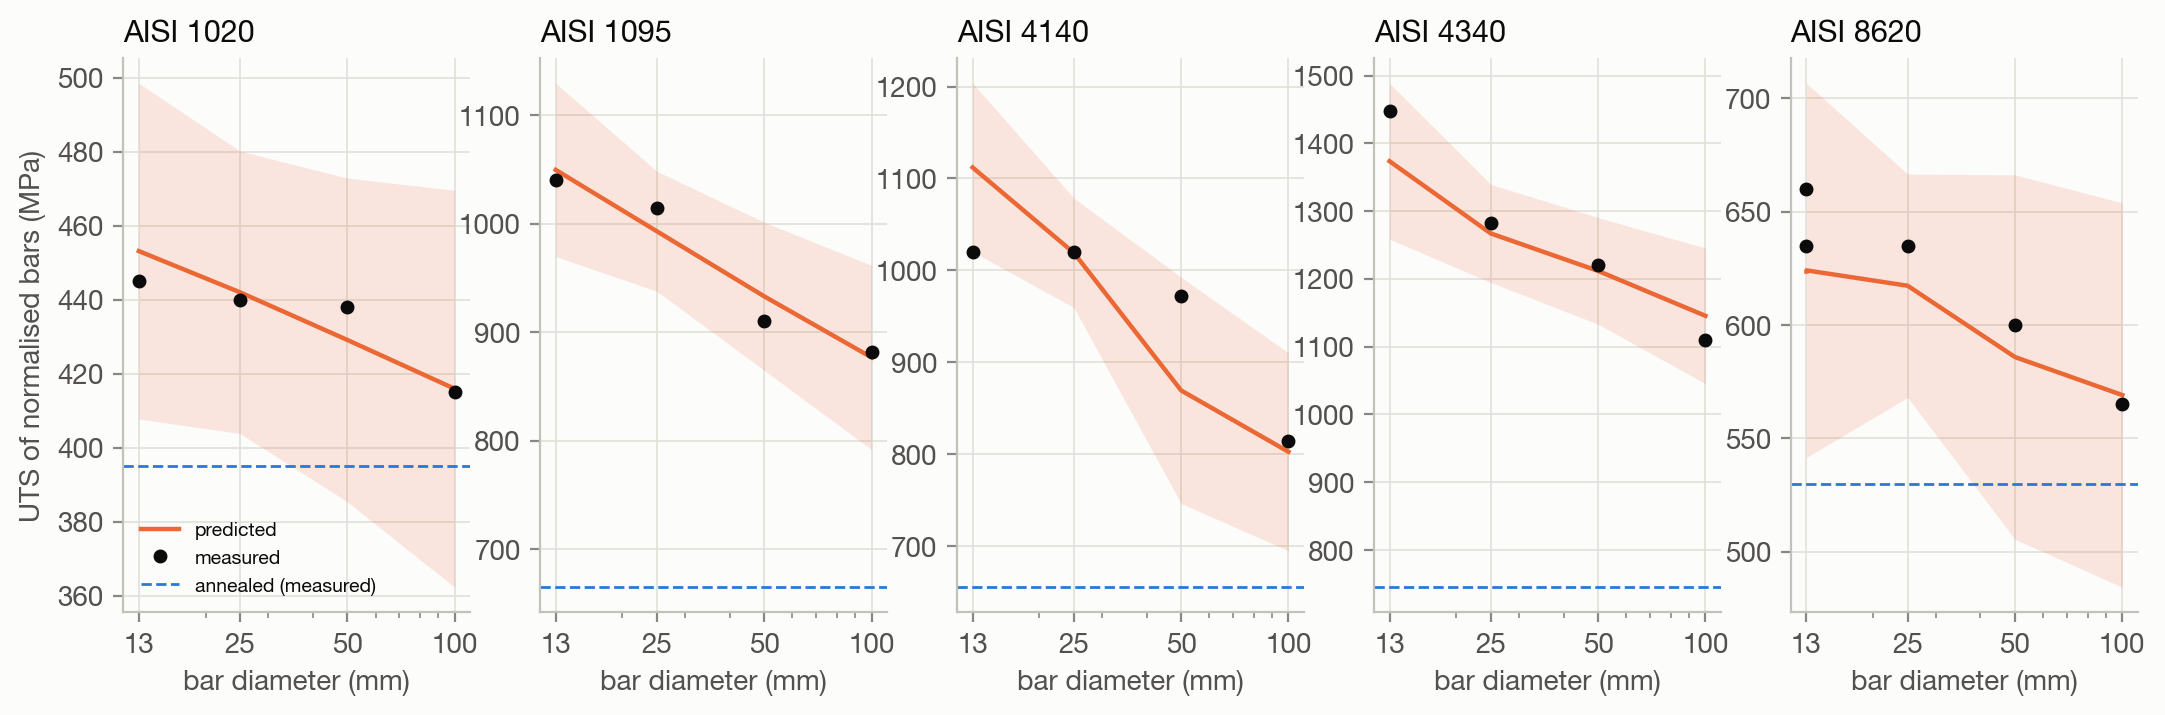

In [10]:
fig("fig42_normalising_bar_size", 1100)